# Ensemble Logistic Regression, Built From Scratch

A tree-structured ensemble of logistic regression models, implemented from raw gradient descent (no `sklearn.linear_model`), predicting wine quality from physicochemical measurements. Each stage adds more specialized sub-models and improves on the last: a single logistic regression baseline (72.7% test accuracy) → a 3-node ensemble (75.6%) → a 7-node deep ensemble (76.1%).

In [55]:
# Import Statements
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

## Section 1: Baseline Logistic Regression

A single logistic regression classifier, implemented from scratch (manual sigmoid activation, log-likelihood cost, and gradient descent — no library shortcut), trained to predict wine quality from the dataset's ten physicochemical features. This is the baseline every later section tries to beat.

In [57]:
# Load Dataset from CSV
df = pd.read_csv('allwine.csv', index_col=0)

# Basic DataFrame Exploration
print(df.shape)
print(df.head())
print(df.info())
print(df.describe())

(3198, 11)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0      -0.743787          0.805266    -1.455948       -0.541531  -0.334525   
1      -0.520914          1.798500    -1.455948       -0.047918   0.129345   
2      -0.520914          1.136344    -1.251203       -0.259467   0.002835   
3       1.373509         -1.512280     1.410480       -0.541531  -0.355610   
4      -0.743787          0.805266    -1.455948       -0.541531  -0.334525   

   free sulfur dioxide   density        pH  sulphates   alcohol  quality  
0            -0.539436 -0.978159  0.146723  -0.755850 -1.297136        0  
1             0.787432 -0.998211 -1.220838  -0.062351 -0.960761        0  
2            -0.160331 -0.994200 -0.956148  -0.235726 -0.960761        0  
3             0.029222 -0.974148 -1.397297  -0.640267 -0.960761        1  
4            -0.539436 -0.978159  0.146723  -0.755850 -1.297136        0  
<class 'pandas.core.frame.DataFrame'>
Index: 3198 entries, 0 to 3197
D

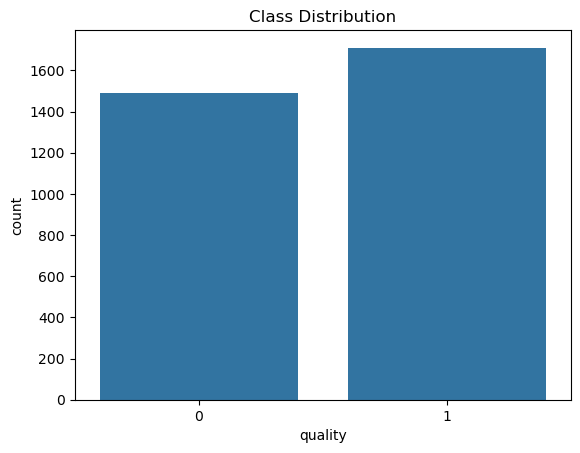

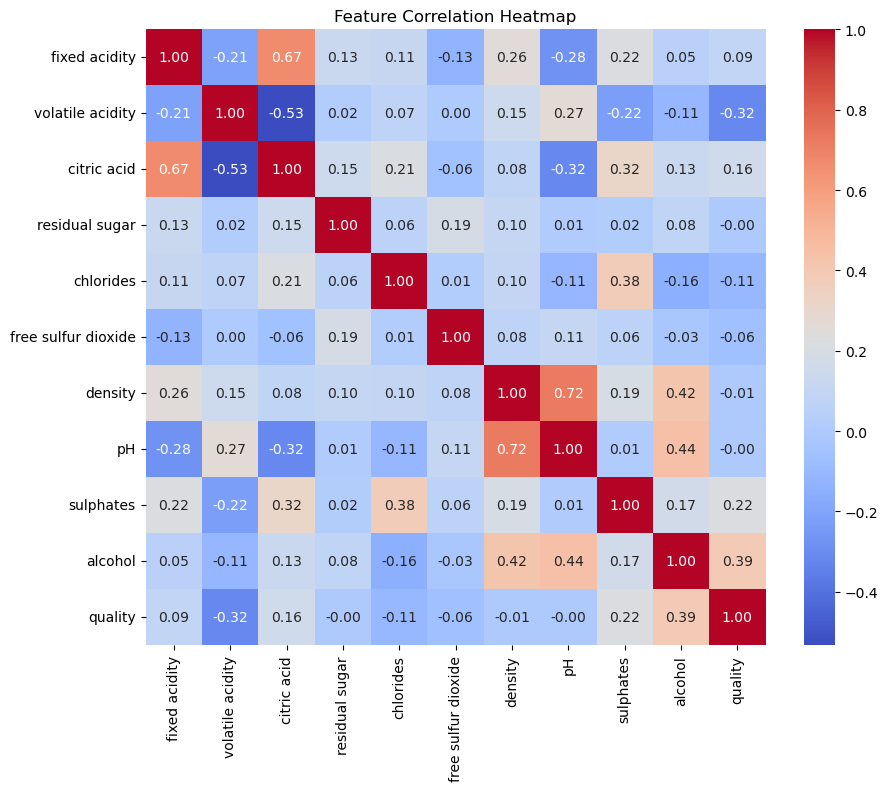

In [58]:
# Exploratory Data Analysis (EDA)

# Distribution of 'quality'
sns.countplot(x='quality', data=df)
plt.title('Class Distribution')
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

In [59]:
# Define Features & Target Variable

# 10 Required Features
feature_cols = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

X = df[feature_cols].values
y = df['quality'].values

In [60]:
# Split Dataset into Training & Test Datasets & Scale / Standardize Values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [61]:
# Core logistic regression building blocks (adapted from a standard vectorized implementation): weight init, sigmoid, cost, gradients, training loop

# Initialize Weights and Bias to Zero
def weightInitialization(n_features):
    w = np.zeros((1, n_features))
    b = 0
    return w, b

# Sigmoid Activation
def sigmoid_activation(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Forward Pass, Compute Cost & Gradients
def model_optimize(w, b, X, Y):
    m = X.shape[0]
    
    # Forward Pass
    z = np.dot(w, X.T) + b
    final_result = sigmoid_activation(z)
    
    Y_T = Y.T
    # Log-likelihood Cost
    cost = (-1/m) * (np.sum((Y_T * np.log(final_result)) + ((1 - Y_T) * np.log(1 - final_result))))
    
    # Gradients
    dw = (1/m) * np.dot(X.T, (final_result - Y_T).T)
    db = (1/m) * np.sum(final_result - Y_T)
    
    grads = {"dw": dw, "db": db}
    return grads, cost

# Gradient Descent Training Loop
def model_predict(w, b, X, Y, learning_rate, no_iterations):
    costs = []
    for i in range(no_iterations):
        grads, cost = model_optimize(w, b, X, Y)
        dw = grads["dw"]
        db = grads["db"]
        
        # Weight update
        w = w - (learning_rate * dw.T)
        b = b - (learning_rate * db)
        
        if i % 100 == 0:
            costs.append(cost)
    
    coeff = {"w": w, "b": b}
    gradient = {"dw": dw, "db": db}
    return coeff, gradient, costs

# Predict Labels from Probabilities
def predict(final_pred, m):
    y_pred = np.zeros((1, m))
    for i in range(final_pred.shape[1]):
        if final_pred[0][i] > 0.5:
            y_pred[0][i] = 1
    return y_pred

In [62]:
# Train Model

# Initialize
n_features = X_train.shape[1]
w, b = weightInitialization(n_features)

# Train
learning_rate = 0.01
iterations = 5000

coeff, gradient, costs = model_predict(w, b, X_train, y_train, learning_rate, iterations)

w_final = coeff["w"]
b_final = coeff["b"]

In [63]:
# Evaluate Performance

# Training accuracy
train_pred_prob = sigmoid_activation(np.dot(w_final, X_train.T) + b_final)
train_pred = predict(train_pred_prob, X_train.shape[0])
train_acc = accuracy_score(y_train, train_pred[0])
print(f"Train Accuracy: {train_acc:.4f}")

# Test accuracy
test_pred_prob = sigmoid_activation(np.dot(w_final, X_test.T) + b_final)
test_pred = predict(test_pred_prob, X_test.shape[0])
test_acc = accuracy_score(y_test, test_pred[0])
print(f"Test Accuracy: {test_acc:.4f}")
task1_test_acc = test_acc

Train Accuracy: 0.7416
Test Accuracy: 0.7266


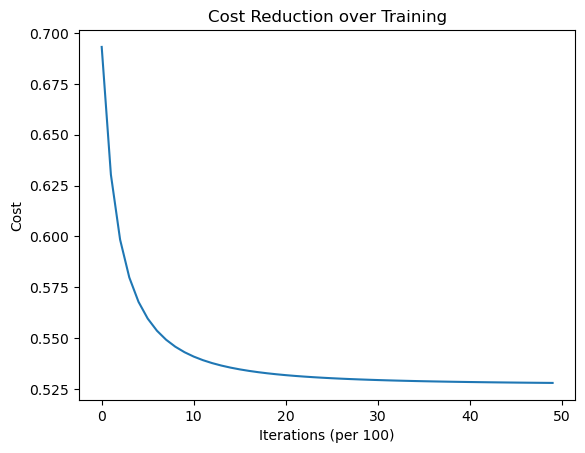

In [64]:
# Plot Cost Reduction

plt.plot(costs)
plt.xlabel('Iterations (per 100)')
plt.ylabel('Cost')
plt.title('Cost Reduction over Training')
plt.show()

## Section 2: Three-Node Ensemble

A small tree of three logistic regression models: `LR_middle` looks at the input and outputs a routing probability, which blends the predictions of two specialized models, `LR_left` and `LR_right`. All three models are trained jointly by maximizing a combined likelihood, with gradients for every node derived by hand via the chain rule. The goal is to test whether letting sub-models specialize on different parts of the data beats a single classifier — it does, improving test accuracy from 72.7% to 75.6%.

In [66]:
# Define Random Weight Initialization
def weightInitialization_random(n_features, seed=365):
    np.random.seed(seed)
    w = np.random.randn(1, n_features) * 0.01
    b = 0
    return w, b

In [67]:
# Define Ensemble Forward Pass & Cost

def ensemble_forward(w_M, b_M, w_L, b_L, w_R, b_R, X):
    # Compute p_M, p_L, p_R for all samples.
    
    # LR_Middle
    p_M = sigmoid_activation(np.dot(w_M, X.T) + b_M)

    # LR_Left
    p_L = sigmoid_activation(np.dot(w_L, X.T) + b_L)

    # LR_Right
    p_R = sigmoid_activation(np.dot(w_R, X.T) + b_R)
    
    return p_M, p_L, p_R


def ensemble_cost(p_M, p_L, p_R, Y):
    # Compute the negative log-likelihood for the ensemble.
    # P(y|x) = p_L^y * (1-p_L)^(1-y) * p_M + p_R^y * (1-p_R)^(1-y) * (1 - p_M)
    # Cost = -1/m * sum(log(P(y_i|x_i)))
    
    m = Y.shape[0]
    Y = Y.reshape(1, -1)

    # LR_Left Model: p_L^y * (1-p_L)^(1-y)
    left_term  = (p_L ** Y) * ((1 - p_L) ** (1 - Y))

    # LR_Right Model: p_R^y * (1-p_R)^(1-y)
    right_term = (p_R ** Y) * ((1 - p_R) ** (1 - Y))

    # Combine Probabilities
    P_i = left_term * p_M + right_term * (1 - p_M)

    # Clip to avoid log(0)
    P_i = np.clip(P_i, 1e-10, 1 - 1e-10)

    cost = (-1 / m) * np.sum(np.log(P_i))
    return cost, P_i

In [68]:
# Define Ensemble Gradient Method

def ensemble_gradients(p_M, p_L, p_R, P_i, Y, X):
    # Compute gradients for all three nodes via chain rule through log(P_i).

    # d_loss/d_theta = -1/m * sum((1/P_i) * dP_i/d_theta)

    # dP_i/d_p_M = left_term - right_term
    # dP_i/d_p_L = p_M * (y/p_L - (1-y)/(1-p_L)) * p_L*(1-p_L) = p_M * (p_L - y)
    # dP_i/d_p_R = (1-p_M) * (p_R - y)

    m = Y.shape[0]
    Y = Y.reshape(1, -1)

    left_term = (p_L ** Y) * ((1 - p_L) ** (1 - Y))
    right_term = (p_R ** Y) * ((1 - p_R) ** (1 - Y))

    # Common Scaling Factor: 1/P_i
    scale = 1.0 / P_i

    # Gradients for LR_Middle
    # dP_i/dp_M = left_term - right_term
    # dp_M/dz_M = p_M*(1-p_M)
    dP_dp_M = left_term - right_term
    delta_M = -scale * dP_dp_M * p_M * (1 - p_M)
    dw_M = (1 / m) * np.dot(X.T, delta_M.T)
    db_M = (1 / m) * np.sum(delta_M)

    # Gradients for LR_Left
    # dP_i/dp_L = p_M * (y/p_L - (1-y)/(1-p_L)) * p_L*(1-p_L) = p_M * (y - p_L)
    delta_L = -scale * p_M * (Y - p_L)
    dw_L = (1 / m) * np.dot(X.T, delta_L.T)
    db_L = (1 / m) * np.sum(delta_L)

    # Gradients for LR_Right
    # dP_i/dp_R = (1-p_M) * (y - p_R)
    delta_R = -scale * (1 - p_M) * (Y - p_R)
    dw_R = (1 / m) * np.dot(X.T, delta_R.T)
    db_R = (1 / m) * np.sum(delta_R)

    grads = {"dw_M": dw_M, "db_M": db_M, "dw_L": dw_L, "db_L": db_L, "dw_R": dw_R, "db_R": db_R}
    
    return grads

In [69]:
# Define Ensemble Training Method

def ensemble_train(X, Y, learning_rate=0.01, no_iterations=5000):
    n_features = X.shape[1]

    # Initialize all three nodes
    w_M, b_M = weightInitialization_random(n_features, seed=52)
    w_L, b_L = weightInitialization_random(n_features, seed=737)
    w_R, b_R = weightInitialization_random(n_features, seed=67)

    costs = []

    for i in range(no_iterations):
        # Forward Pass
        p_M, p_L, p_R = ensemble_forward(w_M, b_M, w_L, b_L, w_R, b_R, X)

        # Cost
        cost, P_i = ensemble_cost(p_M, p_L, p_R, Y)

        # Gradients
        grads = ensemble_gradients(p_M, p_L, p_R, P_i, Y, X)

        # Weight Updates
        w_M = w_M - learning_rate * grads["dw_M"].T
        b_M = b_M - learning_rate * grads["db_M"]

        w_L = w_L - learning_rate * grads["dw_L"].T
        b_L = b_L - learning_rate * grads["db_L"]

        w_R = w_R - learning_rate * grads["dw_R"].T
        b_R = b_R - learning_rate * grads["db_R"]

        if i % 100 == 0:
            costs.append(cost)

    coeffs = {"w_M": w_M, "b_M": b_M, "w_L": w_L, "b_L": b_L, "w_R": w_R, "b_R": b_R}
    
    return coeffs, costs

In [70]:
# Define Ensemble Prediction Method

def ensemble_predict(coeffs, X):
    # Calculate Final Blended Probability - p_L*p_M + p_R*(1-p_M)
    
    w_M, b_M = coeffs["w_M"], coeffs["b_M"]
    w_L, b_L = coeffs["w_L"], coeffs["b_L"]
    w_R, b_R = coeffs["w_R"], coeffs["b_R"]

    p_M, p_L, p_R = ensemble_forward(w_M, b_M, w_L, b_L, w_R, b_R, X)

    # Weighted Blend of Left and Right Predictions
    blended = p_L * p_M + p_R * (1 - p_M)

    return predict(blended, X.shape[0])

Section 2 - Train Accuracy: 0.7705
Section 2 - Test Accuracy: 0.7562


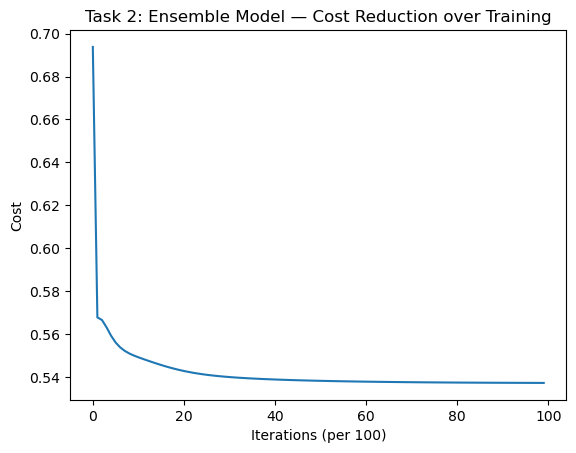

In [71]:
# Train, Evaluate, and Plot Costs for Model

# Train
coeffs, costs = ensemble_train(X_train, y_train, learning_rate=0.5, no_iterations=10000)

# Accuracy
train_preds = ensemble_predict(coeffs, X_train)
test_preds = ensemble_predict(coeffs, X_test)

train_acc = accuracy_score(y_train, train_preds[0])
test_acc = accuracy_score(y_test,  test_preds[0])

print(f"Section 2 - Train Accuracy: {train_acc:.4f}")
print(f"Section 2 - Test Accuracy: {test_acc:.4f}")

task2_test_acc = test_acc

# Cost Curve
plt.plot(costs)
plt.xlabel('Iterations (per 100)')
plt.ylabel('Cost')
plt.title('Section 2: Ensemble Model — Cost Reduction over Training')
plt.show()

In [72]:
print(f"Section 1 - Test Accuracy: {task1_test_acc:.4f}")
print(f"Section 2 - Test Accuracy: {task2_test_acc:.4f}")
print(f"Improvement: {(task2_test_acc - task1_test_acc):.4f}")

Section 1 - Test Accuracy: 0.7266
Section 2 - Test Accuracy: 0.7562
Improvement: 0.0297


## Section 3: Seven-Node Deep Ensemble

Generalizes Section 2's idea to a three-layer tree of seven logistic regression nodes: a root node and two internal nodes route each point toward one of four leaf models, and the final prediction is a probability-weighted blend of all four leaves. Same approach as before — a joint likelihood over every root-to-leaf path, with gradients derived by hand for all seven nodes — extended to a deeper tree. Test accuracy improves further to 76.1%.

In [74]:
# Forward Pass: Compute all 7 node outputs
def deep_ensemble_forward(weights, X):
    p = {}
    for i in range(1, 8):
        w, b = weights[f'w{i}'], weights[f'b{i}']
        p[i] = sigmoid_activation(np.dot(w, X.T) + b)
    return p


# Cost: Negative Log-likelihood over 4 leaf paths
def deep_ensemble_cost(p, Y):
    m = Y.shape[0]
    Y = Y.reshape(1, -1)

    # Leaf classification terms: p_leaf^y * (1-p_leaf)^(1-y)
    t4 = (p[4] ** Y) * ((1 - p[4]) ** (1 - Y))
    t5 = (p[5] ** Y) * ((1 - p[5]) ** (1 - Y))
    t6 = (p[6] ** Y) * ((1 - p[6]) ** (1 - Y))
    t7 = (p[7] ** Y) * ((1 - p[7]) ** (1 - Y))

    # Routing weights for each path
    # Left-Left
    w4 = p[1] * p[2]    
    # Left-Right
    w5 = p[1] * (1 - p[2])         
    # Right-Left
    w6 = (1 - p[1]) * p[3]
    # Right-Right
    w7 = (1 - p[1]) * (1 - p[3])

    # Combined probability per sample
    P_i = t4 * w4 + t5 * w5 + t6 * w6 + t7 * w7
    P_i = np.clip(P_i, 1e-10, 1 - 1e-10)

    cost = (-1 / m) * np.sum(np.log(P_i))
    return cost, P_i, t4, t5, t6, t7, w4, w5, w6, w7

In [75]:
# Gradients for all 7 nodes
def deep_ensemble_gradients(p, P_i, Y, X, t4, t5, t6, t7, w4, w5, w6, w7):
    # Gradient = -1/m * sum(log(P_i)) w.r.t. each node's weights.
    # Chain Rule - d_cost/d_theta = -1/m * (1/P_i) * dP_i/d_theta
    
    m = Y.shape[0]
    Y = Y.reshape(1, -1)

    inv_Pi = 1.0 / P_i

    # Leaf Nodes
    # Probability - dP_i/dp_leaf = routing_weight * (y - p_leaf)
    
    # Node 4 — Left-Left - Routing Weight = p1*p2
    dP_dp4 = w4 * (Y - p[4])
    delta4 = -(inv_Pi * dP_dp4)
    dw4 = (1/m) * np.dot(X.T, delta4.T)
    db4 = (1/m) * np.sum(delta4)

    # Node 5 — Left-Right - Routing Weight = p1*(1-p2)
    dP_dp5 = w5 * (Y - p[5])
    delta5 = -(inv_Pi * dP_dp5)
    dw5 = (1/m) * np.dot(X.T, delta5.T)
    db5 = (1/m) * np.sum(delta5)

    # Node 6 — Right-Left- Routing Weight = (1-p1)*p3
    dP_dp6 = w6 * (Y - p[6])
    delta6 = -(inv_Pi * dP_dp6)
    dw6 = (1/m) * np.dot(X.T, delta6.T)
    db6 = (1/m) * np.sum(delta6)

    # Node 7 — Right-Right - Routing Weight = (1-p1)*(1-p3)
    dP_dp7 = w7 * (Y - p[7])
    delta7 = -(inv_Pi * dP_dp7)
    dw7 = (1/m) * np.dot(X.T, delta7.T)
    db7 = (1/m) * np.sum(delta7)

    # Middle Layer Nodes
    
    # Node 2 routes between Nodes 4 & 5
    # dP_i/dp2 = p1 * (t4 - t5) * p2 * (1 - p2)
    dP_dp2 = p[1] * (t4 - t5) * p[2] * (1 - p[2])
    delta2 = -(inv_Pi * dP_dp2)
    dw2 = (1/m) * np.dot(X.T, delta2.T)
    db2 = (1/m) * np.sum(delta2)

    # Node 3 routes between Nodes 6 & 7
    # dP_i/dp3 = (1-p1) * (t6 - t7) * p3 * (1 - p3)
    dP_dp3 = (1 - p[1]) * (t6 - t7) * p[3] * (1 - p[3])
    delta3 = -(inv_Pi * dP_dp3)
    dw3 = (1/m) * np.dot(X.T, delta3.T)
    db3 = (1/m) * np.sum(delta3)

    # Root Node
    
    # Node 1 routes between Nodes 2 & 3
    # Left Subtree Total: t4 * p2 + t5 * (1 - p2)
    # Right Subtree Total: t6 * p3 + t7 * (1 - p3)
    # dP_i/dp1 = [left_sub - right_sub] * p1 * (1 - p1)
    left_sub = t4 * p[2] + t5 * (1 - p[2])
    right_sub = t6 * p[3] + t7 * (1 - p[3])
    dP_dp1 = (left_sub - right_sub) * p[1] * (1 - p[1])
    delta1 = -(inv_Pi * dP_dp1)
    dw1 = (1/m) * np.dot(X.T, delta1.T)
    db1 = (1/m) * np.sum(delta1)

    grads = {
        'dw1': dw1, 'db1': db1,
        'dw2': dw2, 'db2': db2,
        'dw3': dw3, 'db3': db3,
        'dw4': dw4, 'db4': db4,
        'dw5': dw5, 'db5': db5,
        'dw6': dw6, 'db6': db6,
        'dw7': dw7, 'db7': db7,
    }
    return grads

In [76]:
# Training Loop
def deep_ensemble_train(X, Y, learning_rate=0.3, no_iterations=10000):
    n_features = X.shape[1]
    seeds = [42, 7, 123, 17, 55, 99, 3]

    # Initialize Weights Dictionary
    weights = {}
    for i, seed in enumerate(seeds, start=1):
        w, b = weightInitialization_random(n_features, seed=seed)
        weights[f'w{i}'] = w
        weights[f'b{i}'] = b

    costs = []

    for iteration in range(no_iterations):
        # Forward
        p = deep_ensemble_forward(weights, X)

        # Cost
        cost, P_i, t4, t5, t6, t7, w4, w5, w6, w7 = deep_ensemble_cost(p, Y)

        # Gradients
        grads = deep_ensemble_gradients(p, P_i, Y, X, t4, t5, t6, t7, w4, w5, w6, w7)

        # Update all 7 Nodes
        for i in range(1, 8):
            weights[f'w{i}'] = weights[f'w{i}'] - learning_rate * grads[f'dw{i}'].T
            weights[f'b{i}'] = weights[f'b{i}'] - learning_rate * grads[f'db{i}']

        if iteration % 100 == 0:
            costs.append(cost)

    return weights, costs

In [77]:
# Predict - Calculate Final Blended Probability - Weighted Sum of All 4 Leaf Predictions
def deep_ensemble_predict(weights, X):
    p = deep_ensemble_forward(weights, X)

    blended = (p[4] * p[1] * p[2] + p[5] * p[1] * (1 - p[2]) + p[6] * (1 - p[1]) * p[3] + p[7] * (1 - p[1]) * (1 - p[3]))

    return predict(blended, X.shape[0])

Section 1 - Test Accuracy:  0.7266
Section 2 - Test Accuracy:  0.7562
Section 3 - Test Accuracy:  0.7609


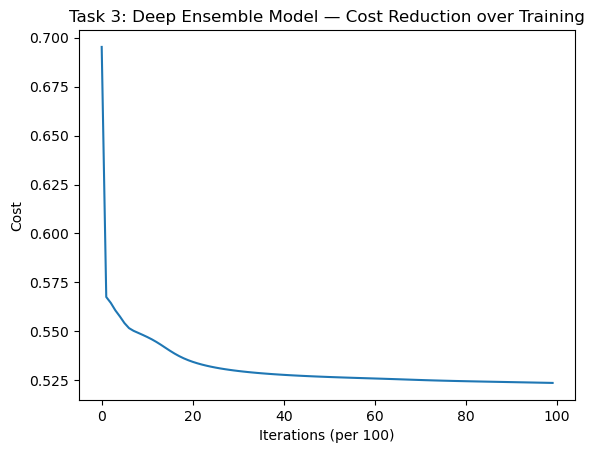

In [86]:
# Train, Evaluate, and Plot
weights_t3, costs_t3 = deep_ensemble_train(X_train, y_train, learning_rate=0.7, no_iterations=10000)

train_preds = deep_ensemble_predict(weights_t3, X_train)
test_preds = deep_ensemble_predict(weights_t3, X_test)

train_acc = accuracy_score(y_train, train_preds[0])
test_acc = accuracy_score(y_test,  test_preds[0])

task3_test_acc = test_acc

print(f"Section 1 - Test Accuracy:  {task1_test_acc:.4f}")
print(f"Section 2 - Test Accuracy:  {task2_test_acc:.4f}")
print(f"Section 3 - Test Accuracy:  {task3_test_acc:.4f}")

plt.plot(costs_t3)
plt.xlabel('Iterations (per 100)')
plt.ylabel('Cost')
plt.title('Section 3: Deep Ensemble Model — Cost Reduction over Training')
plt.show()